# Analytic gradients in vacuum

This notebook compares oscillation probabilities and their physical parameter derivatives at a baseline of 295 km and a neutrino energy of 0.6 GeV.

The default channel is **muon-neutrino to electron-neutrino appearance**, $P(
u_\mu 	o
u_e)$: the probability that a neutrino produced with muon flavor is detected with electron flavor after propagation. It is dimensionless. Flavor indices are `0 = electron`, `1 = muon`, and `2 = tau`; the configuration `emittedFlavor, detectedFlavor = 1, 0` therefore selects this appearance channel. Set both indices to `1` for muon-neutrino survival, $P(
u_\mu 	o
u_\mu)$. Set `isAntiNu = True` for the corresponding antineutrino channel, then rerun the setup and plotting cells.

Each row varies one of the six independent parameters while holding all others fixed. The left panel shows the channel probability; the right panel compares its analytic derivative with the centered finite difference $[P(p+\epsilon)-P(p-\epsilon)]/(2\epsilon)$. Derivatives are taken with respect to physical parameter values (angles and phases in radians, mass-squared differences in eV²), without weight normalization or fit-space scaling.

Jacobian columns follow the explicit order of `parameterBasis`, which may be a subset of the model parameters. This initial gradient implementation uses NumPy on the CPU in double precision; the existing `probability` calculation path is unchanged.

In [8]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Allow execution from the repository root or notebooks directory.
repoRoot = Path.cwd()
if not (repoRoot / 'src').exists():
    repoRoot = repoRoot.parent
sys.path.insert(0, str(repoRoot / 'src'))

from nu_waves.models.mixing import Mixing
from nu_waves.models.spectrum import Spectrum
from nu_waves.hamiltonian import vacuum
from nu_waves.propagation.oscillator import Oscillator, NeutrinoEventBatch
from nu_waves.propagation.Gradient import MixingAngle, DiracPhase, MassSquaredDifference

parameterBasis = [MixingAngle(1, 2), MixingAngle(1, 3), MixingAngle(2, 3),
                  DiracPhase(1, 3), MassSquaredDifference(2, 1), MassSquaredDifference(3, 2)]
parameterNames = [r'$	heta_{12}$ [rad]', r'$	heta_{13}$ [rad]', r'$	heta_{23}$ [rad]',
                  r'$\delta_{CP}$ [rad]', r'$\Delta m^2_{21}$ [eV²]', r'$\Delta m^2_{32}$ [eV²]']
referenceValues = np.array([0.58725, 0.14819, 0.81341, -1.601, 7.53e-5, 2.509e-3])
scanWidths = [0.2, 0.07, 0.25, np.pi, 4e-5, 1e-3]
epsilons = [1e-6, 1e-6, 1e-6, 1e-6, 1e-9, 1e-9]
isAntiNu = False
emittedFlavor, detectedFlavor = 1, 0


def makeOscillator(values):
    mixing = Mixing(3, {(1, 2): values[0], (1, 3): values[1], (2, 3): values[2]},
                    {(1, 3): values[3]})
    spectrum = Spectrum(3, {(2, 1): values[4], (3, 2): values[5]})
    return Oscillator(vacuum.Hamiltonian(mixing, spectrum, False))


events = NeutrinoEventBatch([295.], [0.6], [emittedFlavor], [detectedFlavor], [isAntiNu])
compiledEvents = makeOscillator(referenceValues).compileEvents(events)

MixingAngle(i=1, j=2): epsilon=1e-06, max absolute error=2.417e-11
MixingAngle(i=1, j=3): epsilon=1e-06, max absolute error=4.237e-11
MixingAngle(i=2, j=3): epsilon=1e-06, max absolute error=5.408e-11
DiracPhase(i=1, j=3): epsilon=1e-06, max absolute error=3.628e-11
MassSquaredDifference(i=2, j=1): epsilon=1e-09, max absolute error=2.970e-08
MassSquaredDifference(i=3, j=2): epsilon=1e-09, max absolute error=2.397e-08


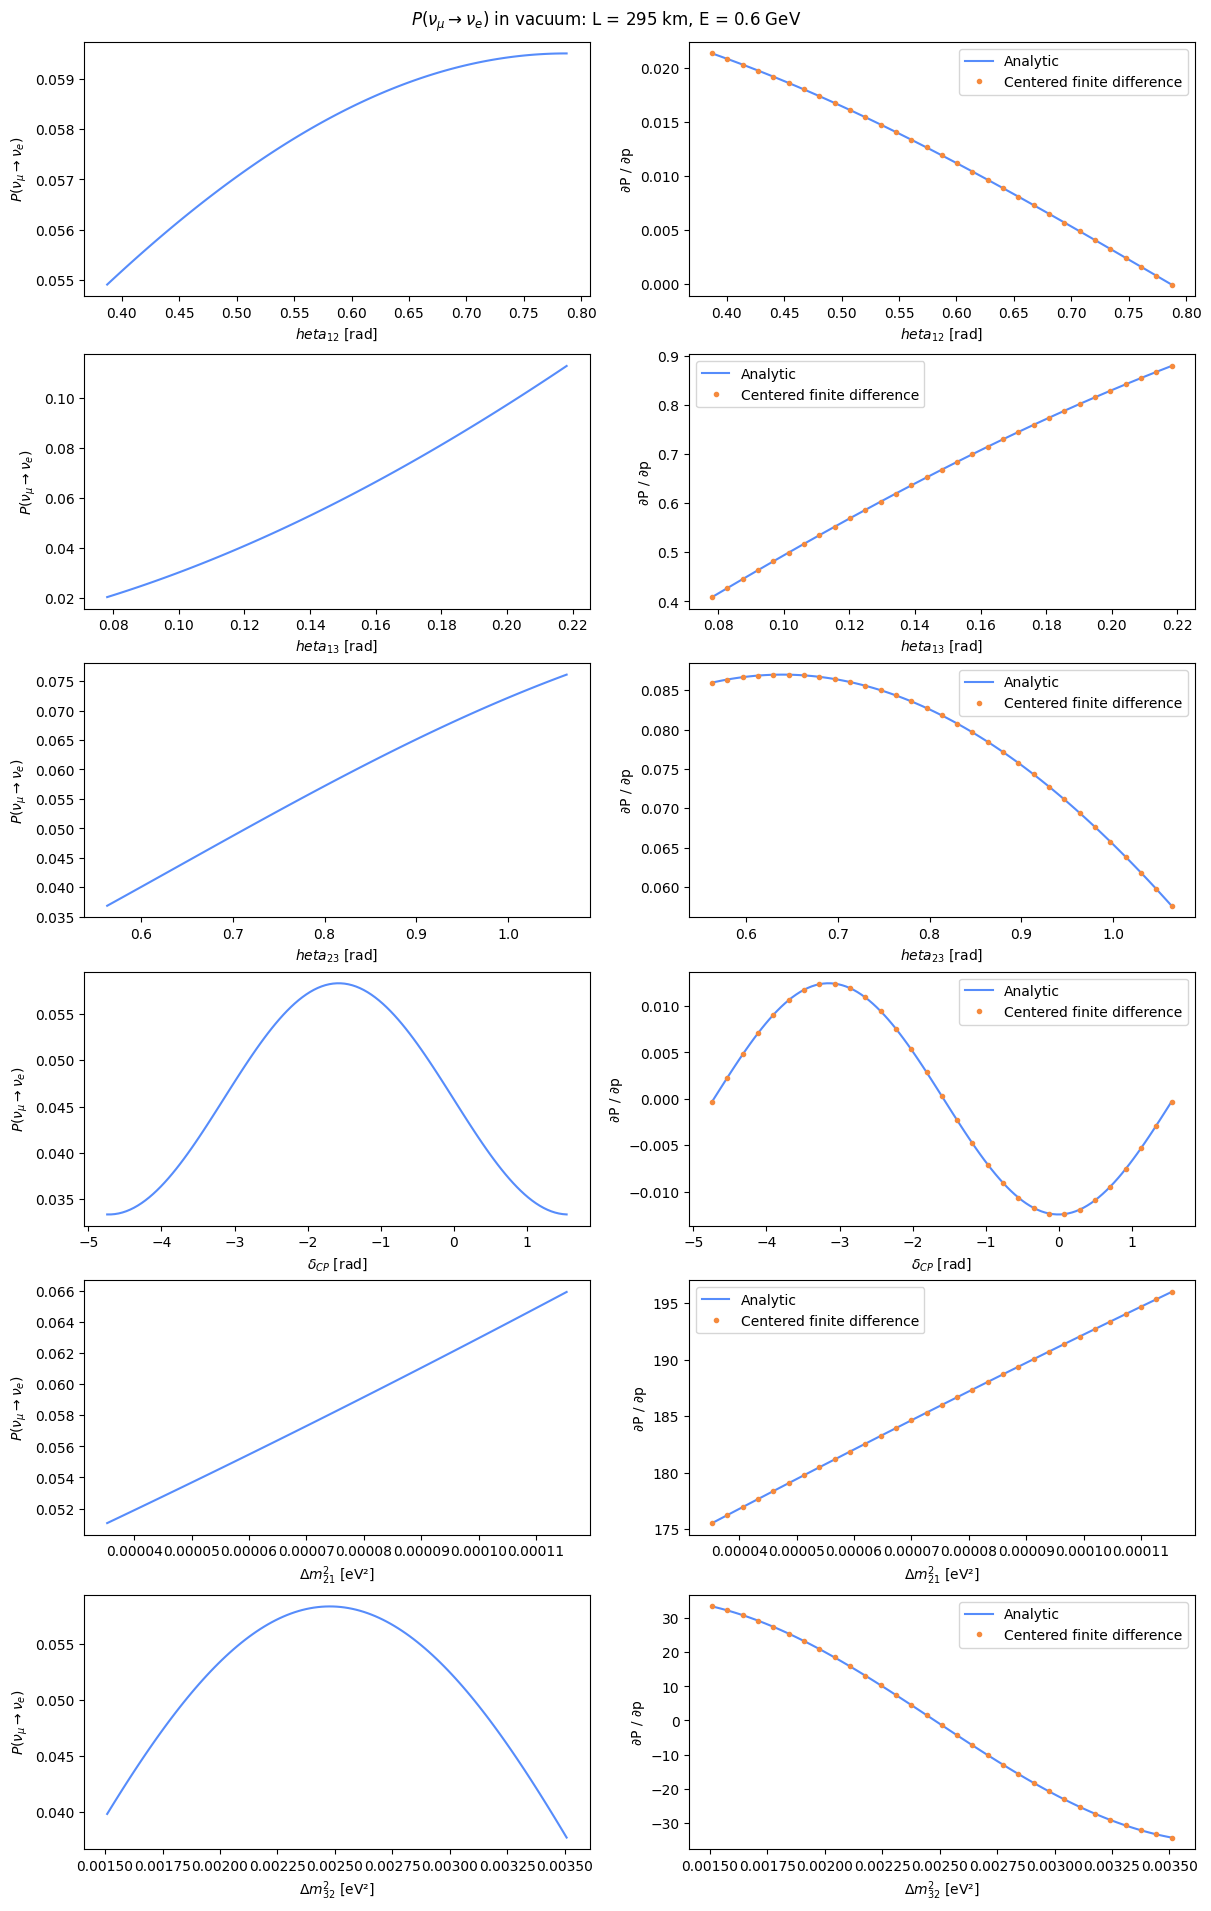

In [9]:
slash = chr(92)
flavorLabels = [slash + 'nu_e', slash + 'nu_' + slash + 'mu', slash + 'nu_' + slash + 'tau']
if isAntiNu:
    flavorLabels = [slash + 'bar{' + label + '}' for label in flavorLabels]
channelLabel = flavorLabels[emittedFlavor] + ' ' + slash + 'to ' + flavorLabels[detectedFlavor]
probabilityLabel = '$P(' + channelLabel + ')$'
fig, axes = plt.subplots(6, 2, figsize=(12, 19), constrained_layout=True)
for column, (parameter, width, epsilon) in enumerate(zip(parameterBasis, scanWidths, epsilons)):
    scanValues = np.linspace(referenceValues[column] - width, referenceValues[column] + width, 121)
    probabilities, analytic, numerical = [], [], []
    for value in scanValues:
        values = referenceValues.copy()
        values[column] = value
        oscillator = makeOscillator(values)
        probability, gradient = oscillator.probabilityWithGradient(compiledEvents, [parameter])
        probabilities.append(probability[0])
        analytic.append(gradient[0, 0])
        plus, minus = values.copy(), values.copy()
        plus[column] += epsilon
        minus[column] -= epsilon
        numerical.append((makeOscillator(plus).probability(compiledEvents)[0] -
                          makeOscillator(minus).probability(compiledEvents)[0]) / (2 * epsilon))
    analytic, numerical = np.asarray(analytic), np.asarray(numerical)
    np.testing.assert_allclose(analytic, numerical, rtol=2e-5, atol=2e-6)
    axes[column, 0].plot(scanValues, probabilities)
    axes[column, 0].set(ylabel=probabilityLabel, xlabel=parameterNames[column])
    axes[column, 1].plot(scanValues, analytic, label='Analytic')
    axes[column, 1].plot(scanValues[::4], numerical[::4], '.', label='Centered finite difference')
    axes[column, 1].set(ylabel='∂P / ∂p', xlabel=parameterNames[column])
    axes[column, 1].legend()
    print(f'{parameter}: epsilon={epsilon:g}, max absolute error={np.max(np.abs(analytic - numerical)):.3e}')
fig.suptitle(probabilityLabel + ' in vacuum: L = 295 km, E = 0.6 GeV')
plt.show()